# Day 2 - Decision Tree Regressor (Optional)

### This is an example of running the DecisionTreeRegressor model to complete a regression task on randomly generated data

In [15]:
import numpy as np
import pandas as pd

# Data
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_regression

# Models
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import Lasso
from sklearn.linear_model import Ridge
from sklearn.linear_model import ElasticNet
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score
from sklearn.metrics import roc_auc_score, RocCurveDisplay

# Model evaluation
from sklearn.metrics import accuracy_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Generate some random data for modelling
np.random.seed(123)
number_of_instances = 100
predictor = np.arange(number_of_instances)
epsilon = np.random.uniform(-10,10, size=(number_of_instances,))
target = .4 * predictor + 3 + epsilon

In [3]:
# In order to use these arrays for regression modelling they need to be reshaped to 2D arrays
x = predictor.reshape(number_of_instances, 1)
y = target.reshape(number_of_instances, 1)

#### Splitting data into training and test sets
To understand model performance, dividing the dataset into a training set and a test set is a good strategy.

Let's split dataset by using function train_test_split(). You need to pass 3 parameters: features, target, and `test_size`. Additionally, you can use `random_state` to make the split reproducible.

In [4]:
# split data in training and test set
from sklearn.model_selection import train_test_split
# create training and testing vars
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=0)
print (x_train.shape, y_train.shape, x_test.shape, y_test.shape)

(80, 1) (80, 1) (20, 1) (20, 1)


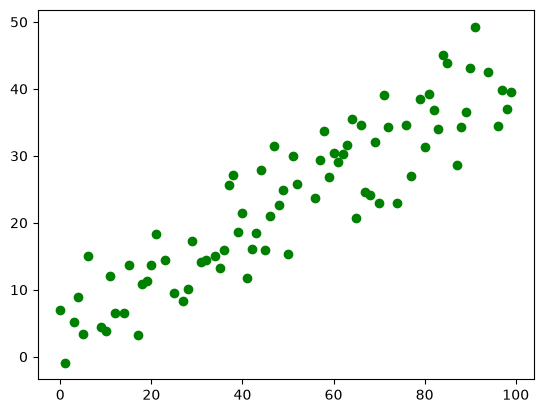

In [5]:
# plot data 
plt.scatter(x_train, y_train,  color='green')
plt.show()

#### Model Development and Prediction
First, import the DecisionTreeRegressor module.
Then, fit your model on the train set using fit() and perform prediction on the test set using predict().

A decision tree regressor repeatedly splits the feature space into regions, choosing each split to minimise the prediction error (by default, the squared error). For a new observation it predicts the mean target value of the training samples in the leaf it falls into.

In [6]:
from sklearn.tree import DecisionTreeRegressor
# Create object that stands for Decision Tree Regressor
model = DecisionTreeRegressor(random_state=42)
# Fit Decision Tree Regressor model
model.fit(x_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with

In [7]:
# Generate predictions
y_pred = model.predict(x_test)

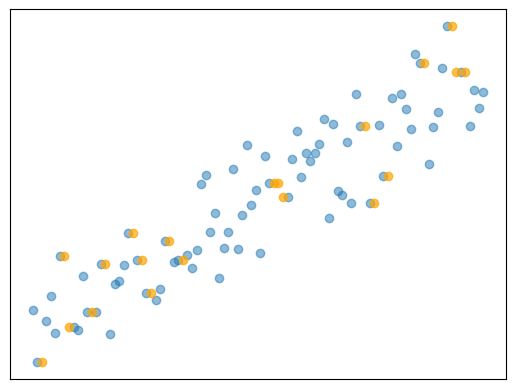

In [8]:
# Plot outputs
plt.scatter(x_train, y_train, color='tab:blue',  alpha = 0.5)
plt.scatter(x_test, y_pred, color='orange', alpha = 0.7)

plt.xticks(())
plt.yticks(())

plt.show()

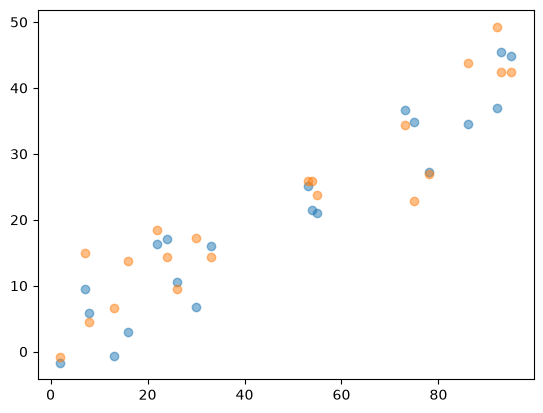

In [9]:
plt.scatter(x_test, y_test, alpha = 0.5)
plt.scatter(x_test, y_pred, alpha = 0.5)
plt.show()

In [ ]:
y_pred = y_pred.reshape(y_test.shape)
np.concatenate([y_pred, y_test], axis = 1)

array([[ 9.45917828, 10.63577311],
       [43.83339994, 34.54795133],
       [-0.8772133 , -1.66297093],
       [23.74044422, 21.08241578],
       [22.92258413, 34.88863759],
       [42.46353833, 45.45095628],
       [13.75990811,  3.04983461],
       [34.34497944, 36.66832716],
       [25.86120257, 21.45527668],
       [42.46353833, 44.83403597],
       [25.86120257, 25.10136013],
       [49.30716964, 36.91829731],
       [26.97919288, 27.2614103 ],
       [ 6.57144489, -0.60644207],
       [15.01528397,  9.49659477],
       [17.21952248,  6.8420988 ],
       [18.38863588, 16.2891065 ],
       [14.42047021, 17.04886765],
       [14.41725527, 16.07370195],
       [ 4.44235036,  5.81863803]])

In [11]:
from sklearn.metrics import r2_score
# Check R^2
print("R^2 score:", r2_score(y_test, y_pred))

R^2 score: 0.8178015311577391


#### To get more details about model parameters please check sklearn [docs](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html)

## Your task: Decision Tree Regressor model for Advertising data

You will use [Advertising](https://www.kaggle.com/purbar/advertising-data) Dataset. The dataset contains statistics about the sales of a product in 200 different markets, together with advertising budgets in each of these markets for different media channels: TV, radio and newspaper.

### Build a prediction model

#### 1. Download (if it's not already downloaded) and load advertising data.

In [12]:
df = pd.read_csv("advertising.csv", index_col=0)
df.head()

,TV,Radio,Newspaper,Sales
1,230.1,37.8,69.2,22.1
2,44.5,39.3,45.1,10.4
3,17.2,45.9,69.3,9.3
4,151.5,41.3,58.5,18.5
5,180.8,10.8,58.4,12.9


#### 2. Split the dataset into labels and features.

In [13]:
x = df.drop(columns=["Sales"])
y = df["Sales"]

#### 3. Look at data and visualize them. Write what you observe.

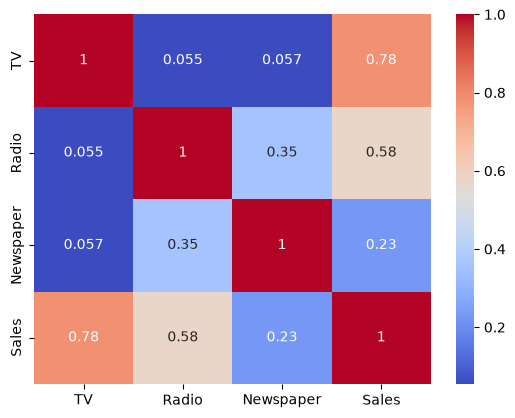

In [17]:
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.show()

Advertising TV has the strongest link with increased sales. Radio also has impactfull correlation with sales. Newspapper seems to be barely affected (at least compared to hughe increase from TV)

#### 4. Split the dataset into training and test sets.

In [19]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.33, random_state=17)

#### 5. Build Decision Tree Regressor model. Use 'Sales' as target variable.

In [21]:
from sklearn.tree import DecisionTreeRegressor
model = DecisionTreeRegressor(random_state=17)
model.fit(x_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",17
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with

#### 6. Provide predictions for test set.

In [22]:
y_pred = model.predict(x_test)

#### 7. Evaluate the model (calculate R^2, MAE, MSE, RMSE).

In [24]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
print("R2:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

R2: 0.9652540244447867
MAE: 0.706060606060606
MSE: 0.8127272727272723
RMSE: 0.9015138782776848


# CONCLUSION
Compare the results of the Linear Regression and Decision Tree Regressor exercises.

Answer the following questions:
- Which model did better on *Advertising.csv* - LinearRegression or DecisionTreeRegressor? 
- How did you evaluate which was better?
- Why did this model do better?

DecisionTreeRegressor did better. R2, MSE and MAE had much better results.
Using same train/test split on the same data. And it moved all the testing values closer to 1.
The data are not too complex but it still is very limited in linear regression on a flat lace. Tree split allows data to be split more precisely without overfitting. 